# Colocate mooring observations with SWOT passages

This notebook demonstrates two operations: finding every SWOT passage over a fixed `(x, y)` mooring during an interval, and associating moving `(x, y, t)` observations with their closest passage.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

import pandas as pd

SatPass version: 0.1.0


## Fixed mooring

Give the mooring longitude and latitude plus an inclusive UTC interval. The result contains every nominal SWOT passage whose nadir track is within the requested distance.

In [2]:
mooring_longitude = 151.0
mooring_latitude = -56.0
start_time = pd.Timestamp("2026-07-01")
end_time = pd.Timestamp("2026-07-31")

mooring_passages = satpass.colocate_xy(
    x=mooring_longitude,
    y=mooring_latitude,
    date_range=[start_time, end_time],
    max_distance_km=65.0,
)
mooring_passages

,x,y,track,direction,cycle,lon0_360,time,subcycle_rank,subcycle,subcycle_global,distance_to_nadir_km
0,151.0,-56.0,366,des,52.0,149.918693,2026-07-02 09:08:00,1,2.0,2.0,62.777644
1,151.0,-56.0,461,asc,52.0,150.625547,2026-07-05 17:57:00,0,1.0,1.0,20.656035
2,151.0,-56.0,60,des,53.0,151.156422,2026-07-12 07:47:00,0,3.0,3.0,9.061347
3,151.0,-56.0,155,asc,53.0,151.862363,2026-07-15 16:36:00,0,0.0,0.0,51.238753
4,151.0,-56.0,366,des,53.0,149.918693,2026-07-23 05:53:00,1,2.0,6.0,62.777644
5,151.0,-56.0,461,asc,53.0,150.625547,2026-07-26 14:42:00,0,1.0,1.0,20.656035


Here `time` is the predicted SWOT passage time. There is no second time variable in the fixed-mooring operation.

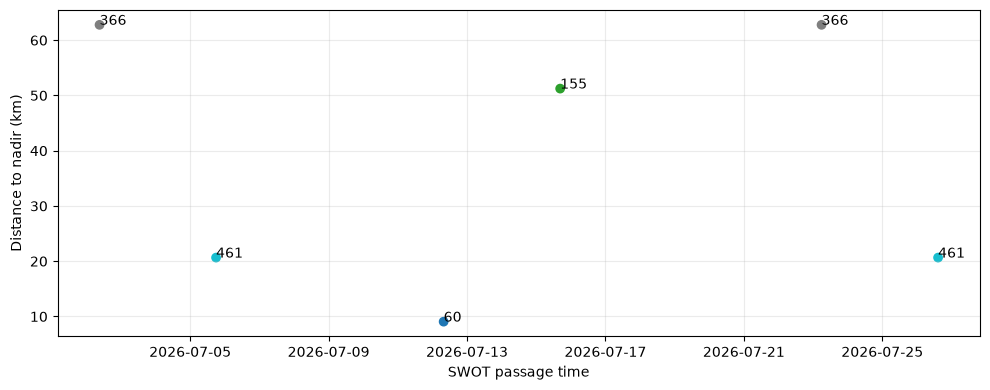

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(
    mooring_passages["time"],
    mooring_passages["distance_to_nadir_km"],
    c=mooring_passages["track"],
    cmap="tab10",
)
for passage in mooring_passages.itertuples():
    ax.annotate(str(passage.track), (passage.time, passage.distance_to_nadir_km))
ax.set(xlabel="SWOT passage time", ylabel="Distance to nadir (km)")
ax.grid(alpha=0.25)
plt.tight_layout()

## Important interpretation

This is a nominal-orbit colocation. `distance_to_nadir_km <= 65` identifies proximity to the SWOT ground track. It does not say that a valid KaRIn pixel exists at the location: the nadir gap, data flags, actual swath geometry, and product availability must be checked against a downloaded SWOT product for true pixel colocation.